# COCO-MLT: which relation source names the classes the model really confuses?

RTN pushes harder on negatives that hold a related class, so each class's
related classes should be the ones the model actually confuses it with.
This notebook scores candidate relation sources against the confusions of
the trained **MulSupCon** model on the **dev set**, before any RTN training.
It reads the saved MulSupCon runs and the encoders' training features,
**trains nothing**, never uses test labels, and uses `rtn_skeleton.py`
read-only (no skeleton change).

**The sources** (each class's 4 most similar classes count as related, as in
the skeleton):
- *GloVe + WordNet (now)*: the skeleton's current source (words).
- *image: own appearance*: each class's own share of the training features
  of the encoder being tested, separated from the classes it appears with.
  This is the candidate for version 3.
- *image: class averages*: the plain average training feature of each class.
  Shown for reference only: it mixes in the classes a class appears with, so
  most related pairs would become "seen together", which breaks the
  skeleton's relation types.
- *CLIP text (reference only)*: off by default. If switched on, it is only
  measured here, as a reference point; it is never used in RTN.

**How confusion is measured.** For a class c, each dev image without c is
placed by its c-score among all dev images without c (a percentile). A class
k is confused with c when the dev images holding k sit high in c's ranking:
the score is how many percentile points above an average negative they sit.
It needs only negatives, so it works for tail classes with few dev images.

*Check version 2.* Each image's own level is removed first (its average
percentile over all the classes it is a negative of), so a busy image that
scores high for every class does not count as confusing them all; this is
the idea of the skeleton's Control 2. Estimates from few dev images are
shrunk towards zero. Version 1 had neither correction, and the same few
classes topped almost every class's list of confusers. The decision rule
below is unchanged.

**Decision rule (fixed before running).** Version 3 changes the relation
source to *image: own appearance* if, on the tail classes (averaged over the
three encoders), its related classes are more confused than GloVe +
WordNet's with a 95% interval above zero. Otherwise the relation source is
not the bottleneck, and version 3 keeps GloVe + WordNet and moves RTN into
fine-tuning instead.

## Step 0: setup

In [1]:
import importlib
import os
import sys

from IPython.display import Image, display

HERE = os.path.dirname(globals().get("__vsc_ipynb_file__", "")) or os.path.abspath("")
PROJECT = next((p for p in (HERE, os.path.dirname(HERE))
                if os.path.isdir(os.path.join(p, "coco_mlt"))
                and os.path.exists(os.path.join(p, "relation_contrastive_runs.py"))), None)
if PROJECT is None:
    raise SystemExit("Put this notebook in the project folder (the one with coco_mlt/ and "
                     "relation_contrastive_runs.py) or in a folder inside it.")
places = [HERE, PROJECT] + sorted(os.path.join(PROJECT, d) for d in os.listdir(PROJECT)
                                  if os.path.isdir(os.path.join(PROJECT, d)))
found = {}
for name in ("rtn_skeleton.py", "rtn_relation_check.py"):
    copies = sorted({os.path.join(p, name) for p in places
                     if os.path.exists(os.path.join(p, name))})
    if not copies:
        raise SystemExit(f"{name} not found next to this notebook or in the project folder.")
    if len({open(c, "rb").read() for c in copies}) > 1:
        raise SystemExit(f"There are different copies of {name}; keep only one:\n  "
                         + "\n  ".join(copies))
    found[name] = os.path.dirname(copies[0])
for p in [PROJECT] + sorted(set(found.values())):
    if p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)
os.chdir(PROJECT)

import rtn_skeleton as sk
import rtn_relation_check as rc
importlib.reload(sk)
importlib.reload(rc)
print(f"Project folder: {PROJECT}\nSkeleton: {sk.__file__} (version {sk.SKELETON_VERSION})\n"
      f"Relation-source check version {rc.CHECK_VERSION}")

DATASET = dict(name="COCO-MLT", folder="coco_mlt",
               definitions=dict(file="coco_mlt/relations/coco_to_synset.json",
                                url=sk.COCO_WORDNET_URL))
ENCODERS = [
    dict(key="clip", label="CLIP ViT-B/16", features="coco_mlt/features"),
    dict(key="vit_b16", label="ViT-B/16 (ImageNet)",
         features="coco_mlt/encoders/vit_b_16_224/features"),
    dict(key="resnet50", label="ResNet-50 (ImageNet, input 448)",
         features="coco_mlt/encoders/resnet50_448/features"),
]
INCLUDE_CLIP_TEXT = False   # True adds CLIP's class-name embeddings as a reference point only
CLIP_TEXT_FILE = "coco_mlt/features/label_text_embeddings.npy"   # saved in rounds 1-6
QUICK_TEST = False          # True only to test this notebook on the tiny test runs
OUT = os.path.join("coco_mlt", "rtn_skeleton", "relation_sources", f"check_v{rc.CHECK_VERSION}")
os.makedirs(OUT, exist_ok=True)

Project folder: c:\Users\Admin\Documents\MSc-Project---RTN
Skeleton: c:\Users\Admin\Documents\MSc-Project---RTN\RTN2\rtn_skeleton.py (version 2)
Relation-source check version 2


## Step 1: load the MulSupCon runs and build the sources

In [2]:
checks = rc.load(DATASET, ENCODERS, quick_test=QUICK_TEST,
                 clip_text_file=CLIP_TEXT_FILE if INCLUDE_CLIP_TEXT else None)

COCO-MLT, CLIP ViT-B/16: skeleton version 2; results in c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\clip\v2
GloVe words not found (ignored): {'baseball glove': ['handwear'], 'donut': ['friedcake']}
Related classes (top 5% most similar names) of the tail classes and of names with several meanings:
Training images: 1516 for training, 393 for the dev set; test images: 5000. Skeleton fingerprint: ff0a7b1cf907. Relation pairs (training part):
COCO-MLT, ViT-B/16 (ImageNet): skeleton version 2; results in c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\vit_b16\v2
GloVe words not found (ignored): {'baseball glove': ['handwear'], 'donut': ['friedcake']}
Related classes (top 5% most similar names) of the tail classes and of names with several meanings:
Training images: 1516 for training, 393 for the dev set; test images: 5000. Skeleton fingerprint: ff0a7b1cf907. Relation pairs (training part):
COCO-MLT, ResNet-50 (ImageNet, input 448): skeleton version 2; re

,encoder,MulSupCon runs (dev scores),dev images,class pairs measurable (%)
0,CLIP ViT-B/16,3,393,77.6
1,ViT-B/16 (ImageNet),3,393,77.6
2,"ResNet-50 (ImageNet, input 448)",3,393,77.6


## Step 2: how confused is the model with each source's related classes?

Per encoder and class group. *Confusion of the related classes*: how many
percentile points above an average negative the dev images of the related
classes sit (higher = the source names real confusers). *Related among the 4
most confused*: the share of a class's related classes that are among the 4
classes the model confuses it with most. The *random classes* row is chance.

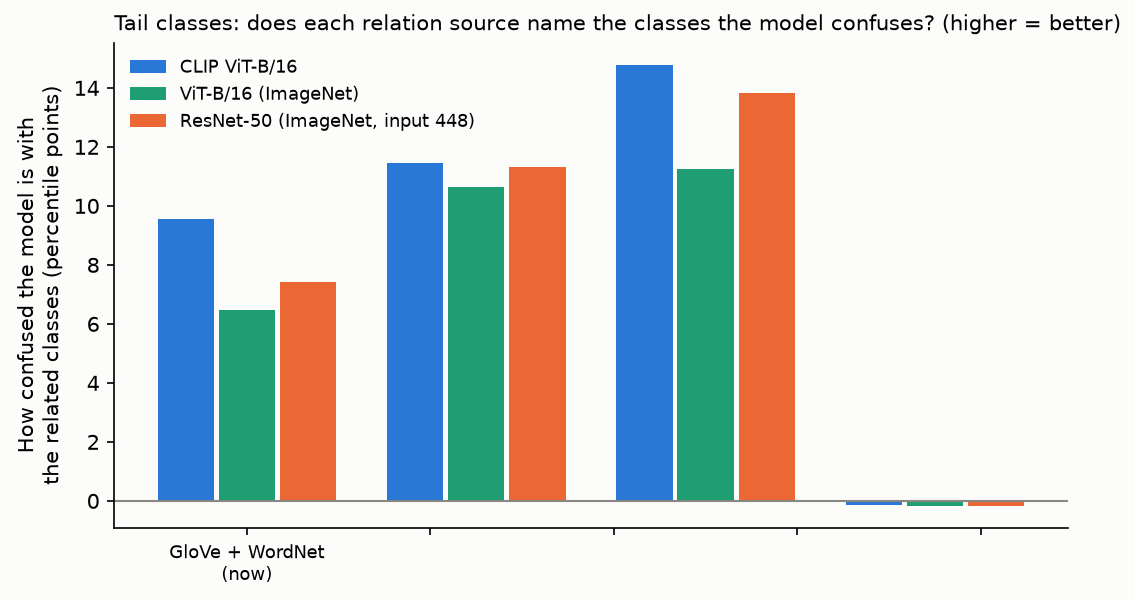

,encoder,cohort,relation source,confusion of the related classes,related among the 4 most confused (%),related classes measurable (%)
0,CLIP ViT-B/16,tail,GloVe + WordNet (now),9.54,41.7,67.0
1,CLIP ViT-B/16,tail,image: own appearance,11.44,56.1,49.0
2,CLIP ViT-B/16,tail,image: class averages (reference),14.78,60.7,59.0
3,CLIP ViT-B/16,tail,random classes (chance),-0.14,6.4,-
4,CLIP ViT-B/16,medium,GloVe + WordNet (now),14.21,41.4,87.9
5,CLIP ViT-B/16,medium,image: own appearance,15.26,44.9,82.6
6,CLIP ViT-B/16,medium,image: class averages (reference),17.83,50.3,90.2
7,CLIP ViT-B/16,medium,random classes (chance),0.17,6.5,-
8,CLIP ViT-B/16,head,GloVe + WordNet (now),13.10,23.9,88.6
9,CLIP ViT-B/16,head,image: own appearance,17.21,36.7,79.5


In [3]:
scores = rc.scores_table(checks)
fig = os.path.join(OUT, "tail_relation_sources.png")
rc.figure(checks, fig)
display(Image(filename=fig))
scores

## Step 3: each image source against GloVe + WordNet, and the decision

Difference in the confusion of the related classes (percentile points),
per class averaged over the three encoders, with a 95% interval over
classes. Above zero = the image source names more real confusers.

In [4]:
against, decision = rc.against_glove(checks)
display(against)
print(decision)

,cohort,relation source,classes,difference from GloVe + WordNet
0,tail,image: own appearance,23,"+2.68 [+1.11, +4.34]"
1,tail,image: class averages (reference),24,"+5.34 [+3.03, +7.81]"
2,medium,image: own appearance,33,"+0.88 [-0.54, +2.36]"
3,medium,image: class averages (reference),33,"+4.13 [+2.61, +5.66]"
4,head,image: own appearance,22,"+4.14 [+1.39, +7.19]"
5,head,image: class averages (reference),22,"+7.94 [+5.01, +11.13]"


Version 3 changes the relation source to 'image: own appearance': on the tail classes its related classes are more confused than GloVe + WordNet's by +2.68 [+1.11, +4.34] percentile points (interval above zero).


## Step 4: the related classes of the tail classes, source by source

Next to the classes the MulSupCon model confuses each tail class with most
on the dev set (for an eye check; blank when too few dev images).

In [5]:
for ch in checks:
    print(ch.label)
    display(rc.examples(ch))

CLIP ViT-B/16


,class,GloVe + WordNet (now),image: own appearance,image: class averages (reference),most confused on dev (MulSupCon)
0,airplane,"car, motorcycle, boat, traffic light","bus, train, suitcase, skis","bus, train, truck, boat","train, horse, truck, boat"
1,train,"car, bus, truck, traffic light","airplane, bus, truck, clock","car, bus, truck, backpack","bus, boat, car, truck"
2,fire hydrant,"car, traffic light, remote, sink","car, parking meter, umbrella, vase","car, traffic light, stop sign, parking meter","traffic light, bus, car, truck"
3,stop sign,"bus, train, traffic light, clock","car, traffic light, parking meter, umbrella","car, truck, traffic light, parking meter","traffic light, bus, truck, car"
4,parking meter,"bicycle, car, bus, traffic light","car, traffic light, fire hydrant, stop sign","car, truck, traffic light, stop sign","traffic light, car, bus, truck"
5,bird,"dog, cow, bear, giraffe","elephant, bear, zebra, giraffe","boat, zebra, giraffe, handbag","bus, boat, truck, traffic light"
6,horse,"cat, dog, cow, elephant","sheep, cow, elephant, zebra","sheep, cow, elephant, zebra","motorcycle, traffic light, truck, car"
7,sheep,"dog, cow, elephant, bear","horse, cow, elephant, zebra","dog, horse, cow, zebra","truck, horse, dog, car"
8,cow,"bird, dog, horse, sheep","horse, sheep, elephant, zebra","horse, sheep, elephant, zebra","umbrella, traffic light, car, truck"
9,elephant,"dog, horse, sheep, giraffe","cow, bear, zebra, giraffe","cow, bear, zebra, giraffe","horse, bicycle, skateboard, boat"


ViT-B/16 (ImageNet)


,class,GloVe + WordNet (now),image: own appearance,image: class averages (reference),most confused on dev (MulSupCon)
0,airplane,"car, motorcycle, boat, traffic light","boat, skis, kite, tennis racket","truck, boat, kite, hair drier","truck, boat, motorcycle, tennis racket"
1,train,"car, bus, truck, traffic light","bus, truck, bird, tennis racket","car, bus, truck, backpack","bus, car, truck, tennis racket"
2,fire hydrant,"car, traffic light, remote, sink","car, stop sign, giraffe, skateboard","car, traffic light, stop sign, handbag","stop sign, traffic light, bus, car"
3,stop sign,"bus, train, traffic light, clock","car, traffic light, fire hydrant, frisbee","car, truck, traffic light, fire hydrant","traffic light, truck, bus, car"
4,parking meter,"bicycle, car, bus, traffic light","train, stop sign, bird, baseball bat","car, truck, traffic light, stop sign","traffic light, truck, car, bus"
5,bird,"dog, cow, bear, giraffe","train, traffic light, tv, clock","car, bus, truck, boat","boat, bus, truck, traffic light"
6,horse,"cat, dog, cow, elephant","sheep, cow, elephant, giraffe","car, cow, elephant, giraffe","boat, car, motorcycle, bicycle"
7,sheep,"dog, cow, elephant, bear","dog, horse, cow, giraffe","car, dog, cow, giraffe","horse, truck, traffic light, car"
8,cow,"bird, dog, horse, sheep","horse, sheep, elephant, giraffe","car, horse, sheep, giraffe","umbrella, sports ball, bus, traffic light"
9,elephant,"dog, horse, sheep, giraffe","boat, horse, cow, bear","horse, sheep, cow, giraffe","horse, sports ball, baseball glove, baseball bat"


ResNet-50 (ImageNet, input 448)


,class,GloVe + WordNet (now),image: own appearance,image: class averages (reference),most confused on dev (MulSupCon)
0,airplane,"car, motorcycle, boat, traffic light","train, boat, kite, surfboard","car, truck, boat, fire hydrant","truck, train, car, boat"
1,train,"car, bus, truck, traffic light","airplane, bus, truck, traffic light","car, bus, truck, traffic light","bus, traffic light, truck, car"
2,fire hydrant,"car, traffic light, remote, sink","car, airplane, parking meter, bench","car, truck, traffic light, stop sign","traffic light, truck, bus, car"
3,stop sign,"bus, train, traffic light, clock","car, traffic light, skis, skateboard","car, truck, traffic light, fire hydrant","traffic light, truck, bus, car"
4,parking meter,"bicycle, car, bus, traffic light","car, motorcycle, fire hydrant, stop sign","car, traffic light, fire hydrant, stop sign","traffic light, car, truck, bus"
5,bird,"dog, cow, bear, giraffe","sheep, elephant, giraffe, surfboard","truck, boat, backpack, handbag","boat, bus, truck, traffic light"
6,horse,"cat, dog, cow, elephant","dog, cow, elephant, giraffe","cow, elephant, backpack, handbag","bicycle, boat, backpack, motorcycle"
7,sheep,"dog, cow, elephant, bear","dog, horse, cow, giraffe","dog, horse, cow, giraffe","horse, sports ball, truck, baseball bat"
8,cow,"bird, dog, horse, sheep","horse, sheep, elephant, giraffe","horse, sheep, elephant, giraffe","umbrella, bus, traffic light, truck"
9,elephant,"dog, horse, sheep, giraffe","horse, cow, bear, giraffe","horse, cow, bear, giraffe","horse, boat, baseball bat, bench"


## Step 5: how each source would change the relation types

Pairs in the training part, per class group (as in Step 3 of the encoder
notebooks).

In [6]:
types = rc.types_table(checks)
types

,relation source,encoder,cohort,"related, seen together","related, never together",informative companion
0,GloVe + WordNet (now),all,tail,21,79,41
1,GloVe + WordNet (now),all,medium,80,52,149
2,GloVe + WordNet (now),all,head,82,6,159
3,image: own appearance,CLIP ViT-B/16,tail,17,83,45
4,image: own appearance,CLIP ViT-B/16,medium,81,51,143
5,image: own appearance,CLIP ViT-B/16,head,83,5,146
6,image: class averages (reference),CLIP ViT-B/16,tail,42,58,30
7,image: class averages (reference),CLIP ViT-B/16,medium,114,18,104
8,image: class averages (reference),CLIP ViT-B/16,head,88,0,138
9,image: own appearance,ViT-B/16 (ImageNet),tail,26,74,42


## Step 6: save

In [7]:
scores.to_csv(os.path.join(OUT, "relation_source_scores.csv"), index=False)
against.to_csv(os.path.join(OUT, "against_glove.csv"), index=False)
types.to_csv(os.path.join(OUT, "relation_types_by_source.csv"), index=False)
for ch in checks:
    rc.examples(ch).to_csv(os.path.join(OUT, f"tail_examples_{ch.exp.enc['key']}.csv"),
                           index=False)
with open(os.path.join(OUT, "decision.txt"), "w", encoding="utf-8") as f:
    f.write(decision + "\n")
print(f"Saved the tables, figure and decision to {os.path.abspath(OUT)}")

Saved the tables, figure and decision to c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\relation_sources\check_v2
